# Transient & MCMC 

Let's study transient fenomena with the use of MCMC and Metropolis-Hastings algorithm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee

In [2]:
data = np.load("../Solutions/transient.npy")
time, flux, error = data.T

In [3]:
# Define the model
def Model(t, b, A, alpha, t0):
    return np.where(t < t0, b, b + A * np.exp(-alpha * (t - t0)))

# Define the log-likelihood
def logLikelihood(theta, t, flux, error):
    b, A, alpha, t0 = theta
    model = Model(t, b, A, alpha, t0)
    logL = -0.5 * np.sum(((flux - model) / error) ** 2)
    return logL 

# Define the log-prior
def logPrior(theta):
    b, A, alpha, t0 = theta
    if 0 < b < 50 and 0 < A < 50 and -5 < np.log(alpha) < 5 and 0 < t0 < 100:
        return -np.log(alpha) 
    return -np.inf 

# Define the log-posterior
def logPosterior(theta, t, flux, error):
    logP = logPrior(theta)
    if not np.isfinite(logP):
        return -np.inf
    return logP + logLikelihood(theta, t, flux, error)

In [4]:
ndim = 4
nwalkers = 50

We need to take into account a thermalization time, plus the autocorralation. We run a smal test to set the burn and the thinning for the chain.

  0%|          | 0/2000 [00:00<?, ?it/s]/var/folders/y3/hmkzfhj13553n22ygq7syz5r0000gn/T/ipykernel_26138/3384519921.py:15: RuntimeWarning: invalid value encountered in log
  if 0 < b < 50 and 0 < A < 50 and -5 < np.log(alpha) < 5 and 0 < t0 < 100:
100%|██████████| 2000/2000 [00:03<00:00, 582.71it/s]


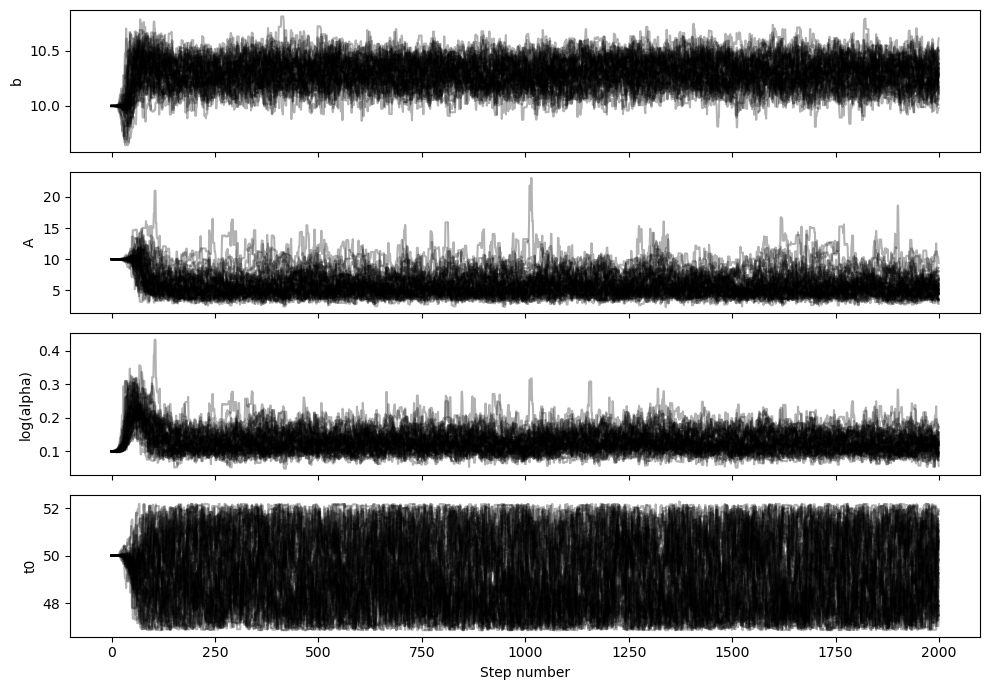

In [5]:
trial = 2000
try_sampler = emcee.EnsembleSampler(nwalkers, ndim, logPosterior, args=(time, flux, error))
initial_pos = np.array([10, 10, 0.1, 50]) + 1e-4 * np.random.randn(nwalkers, ndim)
try_sampler.run_mcmc(initial_pos, trial, progress=True)

traces = try_sampler.get_chain()
labels = ["b", "A", "log(alpha)", "t0"]
fig, axes = plt.subplots(ndim, figsize=(10, 7), sharex=True)
for i in range(ndim):
    ax = axes[i]
    ax.plot(traces[:, :, i], "k", alpha=0.3)
    ax.set_ylabel(labels[i])
axes[-1].set_xlabel("Step number")
plt.tight_layout()
plt.show()

Let's conclude that we need at least 100 steps to burn the chain.

In [6]:
tau = try_sampler.get_autocorr_time()
print(tau)
thin = int(np.max(tau) + 1)

AutocorrError: The chain is shorter than 50 times the integrated autocorrelation time for 4 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 40;
tau: [42.61049967 63.49460535 47.19774606 57.47930058]

In [7]:
# Run the sampler for a longer time to get better estimates, considering the autocorrelation time
burn = 500
nsteps = 10000

sampler = emcee.EnsembleSampler(nwalkers, ndim, logPosterior, args=(time, flux, error))

initial_pos = np.array([10, 10, 0.1, 50]) + 1e-4 * np.random.randn(nwalkers, ndim)

sampler.run_mcmc(initial_pos, nsteps, progress=True)

  0%|          | 0/10000 [00:00<?, ?it/s]/var/folders/y3/hmkzfhj13553n22ygq7syz5r0000gn/T/ipykernel_26138/3384519921.py:15: RuntimeWarning: invalid value encountered in log
  if 0 < b < 50 and 0 < A < 50 and -5 < np.log(alpha) < 5 and 0 < t0 < 100:
100%|██████████| 10000/10000 [00:12<00:00, 795.71it/s]


State([[10.32992672  5.04557993  0.08845107 47.0994908 ]
 [10.26203027  6.34017806  0.11463362 47.13586732]
 [10.55957034  4.00058918  0.13929485 50.75620694]
 [10.23672964  7.18307005  0.12569101 46.95919728]
 [10.24943554  7.97622035  0.13558598 47.61166732]
 [10.07842903  7.10397355  0.17284069 49.73221493]
 [10.31847848  6.02511167  0.12188666 47.67871458]
 [10.17024323  5.91622951  0.09837231 47.10031826]
 [10.46322916  6.12008959  0.17020158 49.67580168]
 [10.42645005  8.28269501  0.13625851 47.30570474]
 [10.42019955  5.57927008  0.11225161 48.12082148]
 [10.56868686  7.97756613  0.16008565 47.89185501]
 [10.17122263  4.27938131  0.10262354 49.83391222]
 [10.37027972  5.02586784  0.13086708 47.73472855]
 [10.37416458  4.98719689  0.0843794  47.08527416]
 [10.38727611  4.6999855   0.1746008  51.11365283]
 [10.13452474  9.84288912  0.17509698 47.62330111]
 [10.15130785  5.55978065  0.09927276 48.90795985]
 [10.20234253  5.86528668  0.12695425 48.80023379]
 [10.36526773  5.15577558

In [8]:
tau = sampler.get_autocorr_time()
print(tau)
thin = int(np.max(tau) + 1)

[55.11004188 74.89405533 59.28055013 72.04827082]


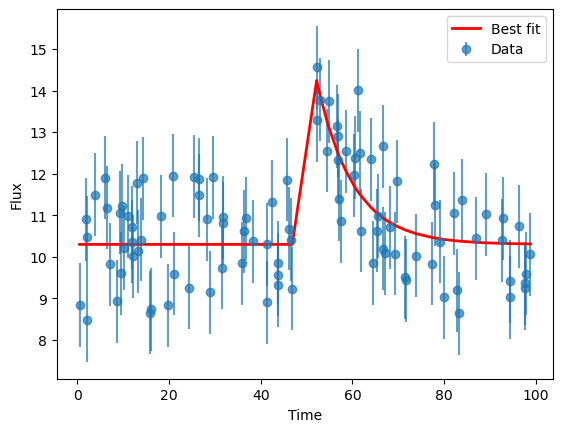

In [9]:
samples = sampler.get_chain(discard=burn, thin=thin, flat=True)

best_params = samples.mean(axis=0)

plt.errorbar(time, flux, yerr=error, fmt='o', label='Data', alpha=0.7)
model_flux = Model(time, *best_params)
plt.plot(time, model_flux, 'r-', label='Best fit', linewidth=2)
plt.xlabel('Time')
plt.ylabel('Flux')
plt.legend()
plt.show()

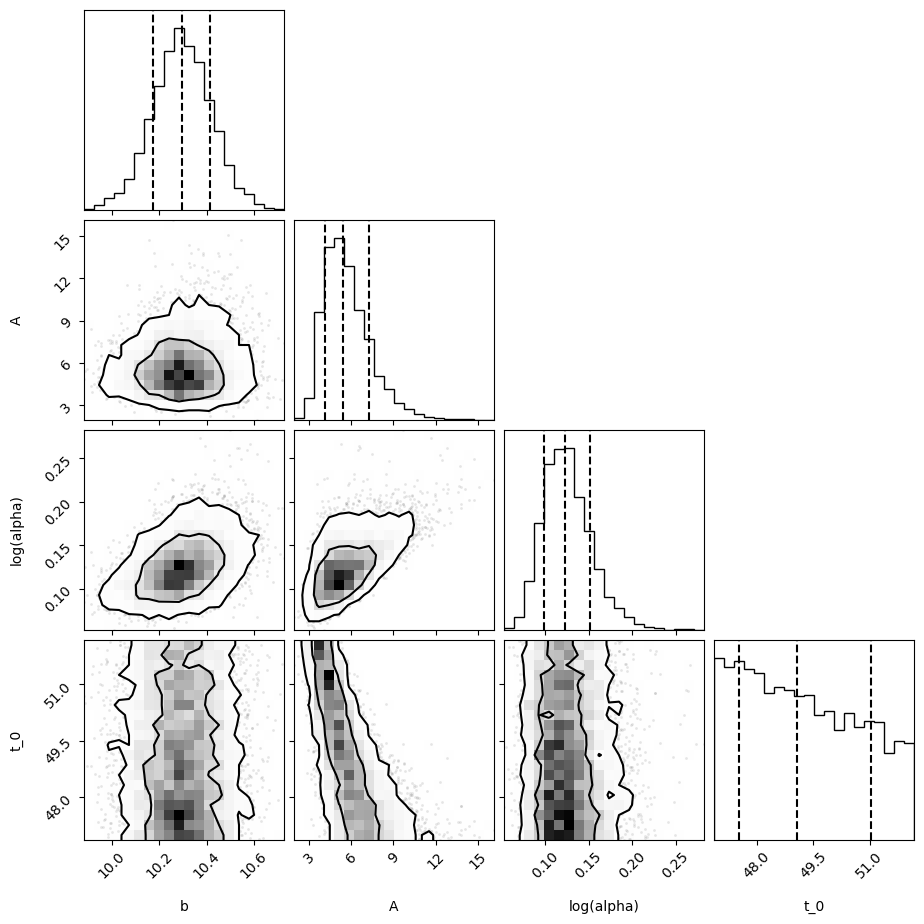

In [10]:
import corner as corner

labels = ["b", "A", "log(alpha)", "t_0"]

fig = corner.corner(
    samples, 
    labels=labels, 
    levels=[0.68, 0.95],
    quantiles=[0.16, 0.5, 0.84]
)
plt.show()

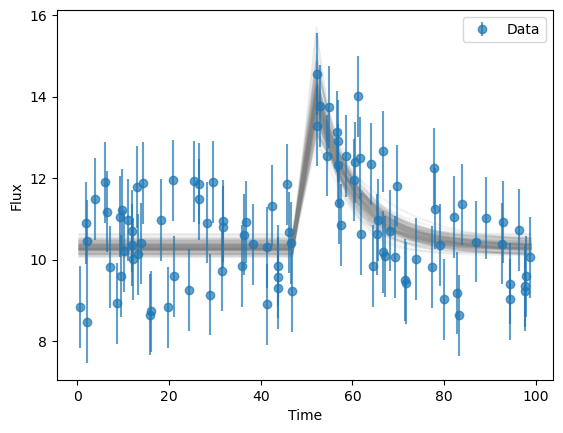

In [11]:
random_samples = samples[np.random.choice(samples.shape[0], size=100, replace=False)]

for i in range(len(random_samples)):
    y = Model(time, *random_samples[i])
    plt.plot(time, y, color='gray', alpha=0.1)
plt.errorbar(time, flux, yerr=error, fmt='o', label='Data', alpha=0.7)
plt.xlabel('Time')
plt.ylabel('Flux')
plt.legend()
plt.show()


In [12]:
median_params = np.median(samples, axis=0)
percentiles_params = np.percentile(samples, [5, 95], axis=0)

for i, param in enumerate(labels):
    print(f"{param}: {median_params[i]:.3f} (+{percentiles_params[1, i] - median_params[i]:.3f}, -{median_params[i] - percentiles_params[0, i]:.3f})")

b: 10.295 (+0.203, -0.205)
A: 5.439 (+3.429, -1.845)
log(alpha): 0.123 (+0.054, -0.037)
t_0: 49.070 (+2.748, -2.002)


We can also check the walker’s behavior.

Mean acceptance fraction: 0.53183
Acceptance fraction (per walker, first 10): [0.5435 0.5399 0.5239 0.5184 0.53   0.52   0.5316 0.5282 0.5405 0.5209]


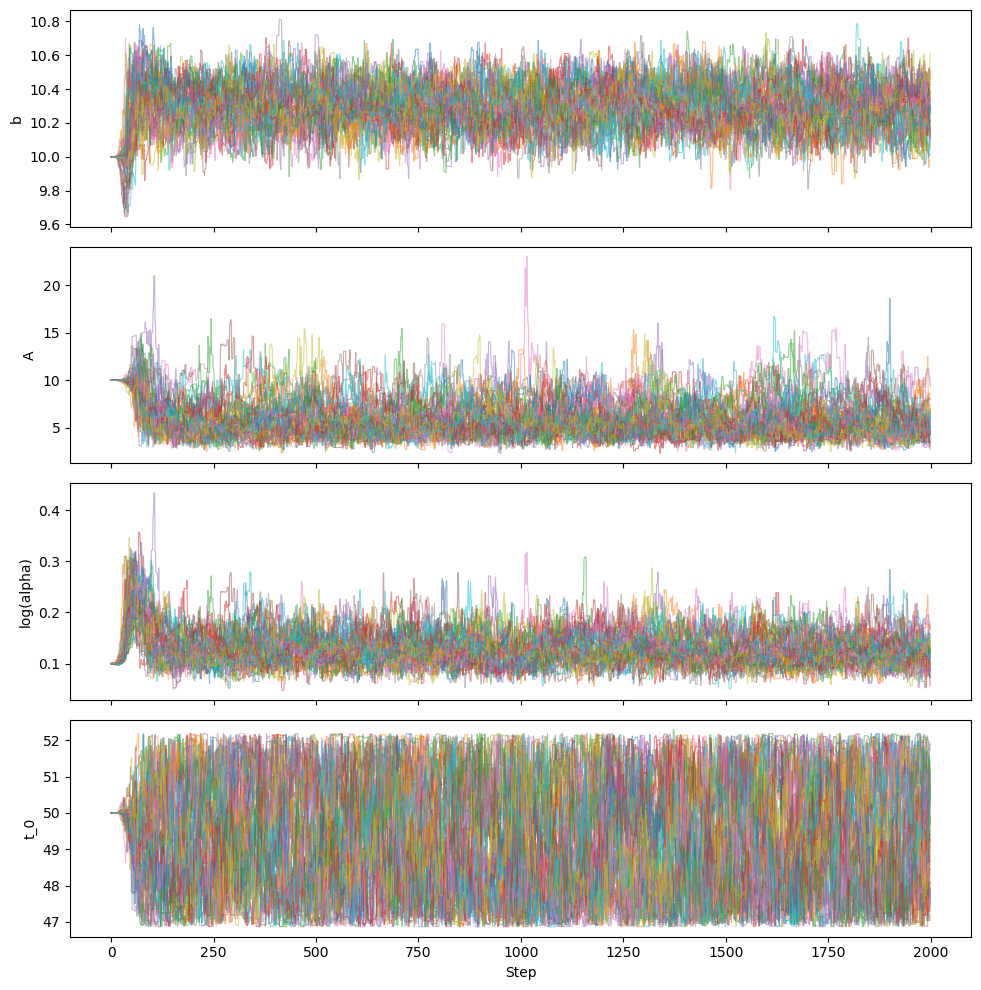

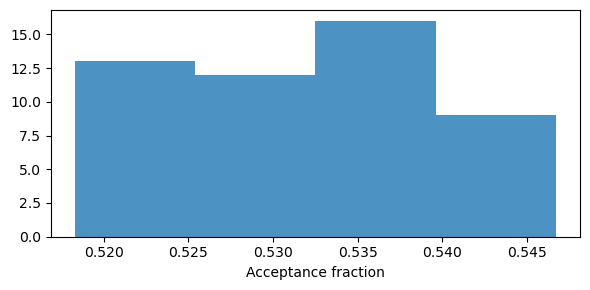

In [14]:
acc = getattr(sampler, "acceptance_fraction", None)
if acc is not None:
    print("Mean acceptance fraction:", acc.mean())
    print("Acceptance fraction (per walker, first 10):", acc[:10])

fig, axes = plt.subplots(ndim, 1, figsize=(10, 2.5 * ndim), sharex=True)
for j in range(ndim):
    ax = axes[j]
    ax.plot(traces[:, :, j], lw=0.8, alpha=0.5)
    ax.set_ylabel(labels[j])
axes[-1].set_xlabel("Step")
plt.tight_layout()
plt.show()

if acc is not None:
    plt.figure(figsize=(6,3))
    plt.hist(acc, bins='scott', alpha=0.8)
    plt.xlabel("Acceptance fraction")
    plt.tight_layout()
    plt.show()

### Savage-Dickey ratio

Use to check that indeed we have a signal over noise.

In [15]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

def kde(samples, bandwith, kernel):
    kde = KernelDensity(bandwidth=bandwith, kernel=kernel)
    kde.fit(samples[:, None])
    return kde

In [16]:
gscv = GridSearchCV(KernelDensity(), {'bandwidth': np.logspace(-2, 2, 20)}, cv=5)
gscv.fit(samples[:, 1].reshape(-1, 1))
gscv.best_params_

{'bandwidth': 0.29763514416313175}

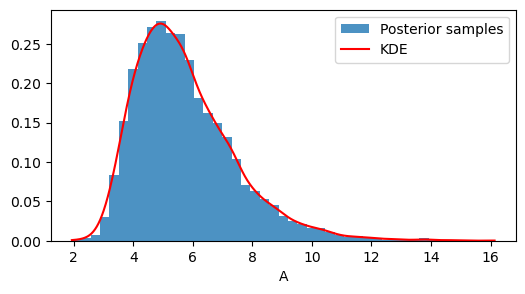

In [17]:
posterior_samples = samples[:, 1]
posterior_kde = kde(posterior_samples, bandwith=gscv.best_params_['bandwidth'], kernel='gaussian')

plt.figure(figsize=(6,3))
plt.hist(posterior_samples, bins='scott', density=True, alpha=0.8, label='Posterior samples')
x = np.linspace(posterior_samples.min(), posterior_samples.max(), 1000)[:, None]
log_dens = posterior_kde.score_samples(x)
plt.plot(x, np.exp(log_dens), 'r-', label='KDE')
plt.xlabel("A")
plt.legend()

In [18]:
A_ref = 0.0
posterior_density = np.exp(posterior_kde.score_samples([[A_ref]]))[0]
prior_density = 1 / 50
bayes_factor = prior_density / posterior_density

print(f'Posterior density at A={A_ref}: {posterior_density:.3e}')
print(f'Prior density at A={A_ref}: {prior_density:.3e}')
print(f'Savage-Dickey Bayes factor: {bayes_factor:.3f}')

Posterior density at A=0.0: 1.337e-13
Prior density at A=0.0: 2.000e-02
Savage-Dickey Bayes factor: 149605348753.266


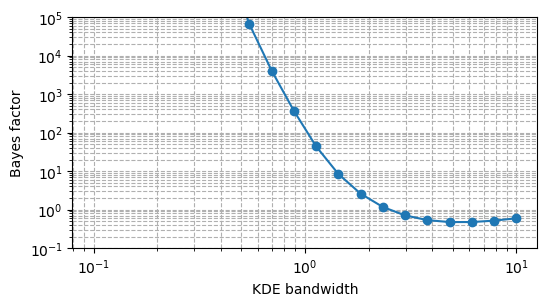

In [19]:
bandwith = np.logspace(-1, 1, 20)
bayesian_factors = []

for bw in bandwith:
    posterior_kde = kde(posterior_samples, bandwith=bw, kernel='gaussian')
    posterior_density = np.exp(posterior_kde.score_samples([[A_ref]]))[0]
    bayes_factor = prior_density / posterior_density
    bayesian_factors.append(bayes_factor)

plt.figure(figsize=(6,3))
plt.loglog(bandwith, bayesian_factors, marker='o')
plt.xlabel('KDE bandwidth')
plt.ylabel('Bayes factor')
plt.ylim(1e-1, 1e5)
plt.grid(True, which="both", ls="--")
plt.show()

We can confirm what we expected: we have identified a clear signal over noise. The last plot shows the importance of cross-validation for understanding the reliability of Bayes Factor, since it is sensitive to the KDE bandwidth choice in the tail region.